# R-SES-001: Mengelompokkan Episenter Gempa dengan DBSCAN
**Keyzha Achmad Fachrezi**

**H061251016**

Recipe ini mengikuti format **Bab 2.4 buku AI Cookbook untuk Earth Sciences**:

**Problem → Minimal Theory → Prompt → Code → Result → Optional Check**

| Keterangan | Isi |
|---|---|
| ID recipe | `R-SES-001` (prompt pendamping: `P-SES-001`) |
| Level | Mahasiswa geofisika semester 3 (cukup Python dasar) |
| Library | `numpy`, `pandas`, `matplotlib`, `scikit-learn` |
| Data | Katalog gempa **sintetis** (dibuat di notebook, tidak perlu download) |
| Status eksekusi | Lihat bagian *Run record* di akhir. Status hanya "Executed" kalau sel-selnya benar-benar sudah dijalankan |

**Cara pakai:** jalankan sel dari atas ke bawah (*Run All*). Setiap bagian diberi penjelasan singkat supaya kamu tahu *kenapa* langkah itu ada, bukan hanya *apa* kodenya.

---
## 1. Problem

**Pertanyaan ilmiah:** pada katalog gempa ini, di mana gempa cenderung mengumpul, dan berapa kelompok (zona) seismik yang terlihat?

**Batas keputusan (penting):** hasil recipe ini hanya untuk **eksplorasi awal**. Ia bukan peta bahaya gempa resmi dan bukan penentuan sumber gempa. Kita hanya mengelompokkan titik berdasarkan kedekatan lokasinya.

### Kontrak input dan constraint

| Hal | Aturan |
|---|---|
| Input | Tabel dengan kolom `lon`, `lat` (derajat, WGS84), `kedalaman_km` (positif ke bawah), `mag` |
| Tidak boleh | Mengubah data input, menghapus baris, atau mengisi nilai hilang (cukup dilaporkan) |
| Library | Hanya numpy, pandas, matplotlib, scikit-learn. Tidak ada akses internet |
| Output | `results/r-ses-001/ringkasan_klaster.csv`, `peta_klaster.png`, dan `run_record.json` |

---
## 2. Minimal Theory

Bagian ini cukup untuk memahami kode, tidak perlu turunan rumus lengkap.

**Hiposenter dan episenter.** Hiposenter adalah titik sumber gempa di dalam bumi (lon, lat, kedalaman). Episenter adalah proyeksinya ke permukaan (hanya lon dan lat). Di recipe ini kita mengelompokkan **episenter**.

**Kenapa jarak haversine?** Bumi berbentuk (hampir) bola. Kalau kita menghitung jarak dua titik dari selisih derajat seperti di kertas grafik, hasilnya melenceng, terutama di lintang tinggi. Jarak haversine adalah jarak di permukaan bola:

$$d = 2R \arcsin\sqrt{\sin^2\!\frac{\Delta\varphi}{2} + \cos\varphi_1\cos\varphi_2\,\sin^2\!\frac{\Delta\lambda}{2}}$$

dengan $R = 6371$ km, $\varphi$ = lintang, $\lambda$ = bujur (dalam radian).

**DBSCAN** punya dua parameter:
- `eps`: radius "lingkungan" sebuah titik.
- `min_samples`: jumlah minimal titik (termasuk dirinya) dalam radius itu agar titik dianggap **padat** (*core point*).

Titik padat yang saling berdekatan digabung menjadi satu klaster. Titik yang tidak masuk klaster mana pun diberi label `-1` (**noise**). Kelebihannya: jumlah klaster tidak perlu ditentukan di awal, dan bentuk klaster boleh memanjang (seperti busur subduksi).

**Asumsi yang dipakai:**
1. Bumi dianggap bola dengan $R = 6371$ km.
2. Urutan koordinat untuk haversine di scikit-learn adalah **(lintang, bujur) dalam radian**. Kalau tertukar, hasilnya salah tanpa pesan error.
3. Magnitudo data sintetis dibuat mengikuti hukum Gutenberg-Richter ($b=1$): gempa kecil jauh lebih banyak daripada gempa besar.

---
## 3. Prompt (`P-SES-001`)

Prompt ini disusun dengan struktur dari Bab 2.1: **P = ⟨R, T, C, I, K, O, Q, V⟩**. Bagian dalam tanda kurung siku `[...]` adalah placeholder yang kamu ganti dengan nilai sendiri. Salin ke Claude kalau mau menjalankan recipe ini pada data lain.

```text
R (Role)        : Asisten analisis data seismologi dengan Python (pandas, scikit-learn).
T (Task)        : Kelompokkan episenter pada [CSV_PATH] dengan DBSCAN (jarak haversine),
                  eps [EPS_KM] km dan min_samples [MIN_SAMPLES].
C (Context)     : Latihan kuliah Seismologi. Hasil hanya untuk eksplorasi zona seismisitas,
                  bukan peta bahaya resmi.
I (Input)       : Hanya [CSV_PATH] dengan kolom lon, lat (derajat WGS84),
                  kedalaman_km (positif ke bawah), mag.
K (Constraints) : Jangan ubah file input. Jangan hapus baris atau isi nilai hilang
                  (laporkan saja). Pakai hanya numpy, pandas, matplotlib, scikit-learn.
                  Tidak ada akses jaringan. Haversine memakai urutan (lat, lon) dalam radian.
O (Output)      : [OUTPUT_DIR]/ringkasan_klaster.csv, [OUTPUT_DIR]/peta_klaster.png,
                  [OUTPUT_DIR]/run_record.json
Q (Quality)     : Jumlah baris data sama sebelum dan sesudah. Setiap klaster berisi minimal
                  min_samples titik. Sumbu dan tabel mencantumkan satuan.
                  Pisahkan observasi dari inferensi.
V (Verification): Hitung manual satu jarak haversine dan bandingkan dengan scikit-learn.
                  Uji sensitivitas eps (0,5x dan 1,5x). Jika ada check yang gagal,
                  berhenti dan laporkan, jangan lanjut.
```

---
## 4. Code

Kodenya dibagi menjadi sel-sel kecil agar mudah dipahami satu per satu.

### 4.1 Setup dan parameter
Semua angka yang bisa kamu ubah ditaruh di satu tempat (sesuai placeholder di prompt).

In [2]:
import os, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import haversine_distances

# --- parameter (sesuai placeholder di prompt) ---
EPS_KM = 100            # radius lingkungan DBSCAN, dalam km
MIN_SAMPLES = 8         # minimal titik agar dianggap padat
OUTPUT_DIR = "results/r-ses-001"
CSV_PATH = os.path.join(OUTPUT_DIR, "katalog_sintetis.csv")
R_BUMI = 6371.0         # km

RNG = np.random.default_rng(42)       # seed tetap: hasil bisa diulang persis
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Parameter siap. Output akan disimpan di:", OUTPUT_DIR)

Parameter siap. Output akan disimpan di: results/r-ses-001


### 4.2 Membuat katalog gempa sintetis
Kita buat 4 zona gempa (3 busur subduksi dan 1 sesar) ditambah gempa "latar belakang" yang tersebar acak.
Karena kita yang membuatnya, kita **tahu zona aslinya**. Ini berguna untuk mengecek hasil DBSCAN nanti. Pada data nyata (misalnya katalog USGS atau BMKG), kebenaran seperti ini tidak ada.

In [3]:
def buat_zona(nama, p0, p1, n, lebar, subduksi):
    """Buat n gempa di sekitar garis dari p0 ke p1 (format lon, lat)."""
    p0, p1 = np.array(p0, float), np.array(p1, float)
    arah = (p1 - p0) / np.linalg.norm(p1 - p0)       # arah garis (vektor satuan)
    tegak = np.array([-arah[1], arah[0]])            # arah tegak lurus garis (ke daratan)
    t = RNG.uniform(0, 1, n)                         # posisi sepanjang garis (0 sampai 1)
    geser = RNG.normal(0, lebar, n)                  # sebaran ke samping garis (derajat)
    lonlat = p0 + t[:, None] * (p1 - p0) + geser[:, None] * tegak
    if subduksi:   # makin ke arah daratan, makin dalam
        dalam = 10 + 90 * np.clip(geser, 0, None) / lebar + RNG.uniform(0, 15, n)
    else:          # sesar dangkal
        dalam = RNG.uniform(2, 20, n)
    mag = np.clip(4.0 + RNG.exponential(1 / np.log(10), n), 4.0, 8.0)   # Gutenberg-Richter, b = 1
    return pd.DataFrame({"lon": lonlat[:, 0], "lat": lonlat[:, 1],
                         "kedalaman_km": dalam, "mag": mag, "zona_asli": nama})

katalog = pd.concat([
    buat_zona("Megathrust Sumatra",    (96.0, 2.5),   (101.5, -3.5), 220, 0.35, True),
    buat_zona("Subduksi Selatan Jawa", (105.5, -7.0), (114.5, -9.5), 180, 0.35, True),
    buat_zona("Busur Banda",           (122.0, -7.5), (129.0, -6.0), 150, 0.40, True),
    buat_zona("Sesar Sulawesi",        (119.8, -0.5), (119.9, -2.5),  80, 0.10, False),
    pd.DataFrame({"lon": RNG.uniform(94, 130, 120), "lat": RNG.uniform(-11, 6, 120),
                  "kedalaman_km": RNG.uniform(5, 80, 120),
                  "mag": np.clip(4.0 + RNG.exponential(1 / np.log(10), 120), 4.0, 8.0),
                  "zona_asli": "Latar belakang"}),
], ignore_index=True).sample(frac=1, random_state=1).reset_index(drop=True)

katalog.to_csv(CSV_PATH, index=False)          # simpan sebagai file input resmi recipe
print(f"Katalog disimpan: {CSV_PATH} ({len(katalog)} gempa)")
katalog.head()

Katalog disimpan: results/r-ses-001\katalog_sintetis.csv (750 gempa)


,lon,lat,kedalaman_km,mag,zona_asli
0,119.799236,-0.862354,11.355566,4.157018,Sesar Sulawesi
1,105.333283,-7.680756,20.351902,5.008672,Subduksi Selatan Jawa
2,105.721084,-7.608952,16.435392,4.968365,Subduksi Selatan Jawa
3,119.860010,-2.277497,2.883333,4.092744,Sesar Sulawesi
4,96.821895,1.571624,24.854825,4.031620,Megathrust Sumatra


### 4.3 Memuat dan memvalidasi input
Sesuai kontrak: cek kolom, tipe, nilai hilang, dan rentang nilai. Data **tidak diubah**. Kalau ada masalah, kita hanya melapor.

In [4]:
data = pd.read_csv(CSV_PATH)                   # baca ulang dari file, seperti pada kasus nyata
n_input = len(data)

cek_input = {
    "kolom_lengkap": {"lon", "lat", "kedalaman_km", "mag"}.issubset(data.columns),
    "tidak_ada_nilai_hilang": int(data[["lon", "lat", "kedalaman_km", "mag"]].isna().sum().sum()) == 0,
    "lon_dalam_rentang": bool(data.lon.between(-180, 180).all()),
    "lat_dalam_rentang": bool(data.lat.between(-90, 90).all()),
    "kedalaman_tidak_negatif": bool((data.kedalaman_km >= 0).all()),
}
for nama, lolos in cek_input.items():
    print(("LOLOS  " if lolos else "GAGAL  ") + nama)
assert all(cek_input.values()), "Validasi input gagal, hentikan recipe dan periksa datanya."
print(f"\nJumlah baris input: {n_input}")

LOLOS  kolom_lengkap
LOLOS  tidak_ada_nilai_hilang
LOLOS  lon_dalam_rentang
LOLOS  lat_dalam_rentang
LOLOS  kedalaman_tidak_negatif

Jumlah baris input: 750


### 4.4 Memilih `eps` dengan grafik k-distance
Untuk tiap titik, kita hitung jarak ke tetangga ke-`MIN_SAMPLES`, lalu urutkan. Kurva biasanya datar lalu tiba-tiba naik tajam: titik "siku" itu adalah kandidat `eps`. Titik di sisi yang naik tajam adalah titik terpencil (calon noise).

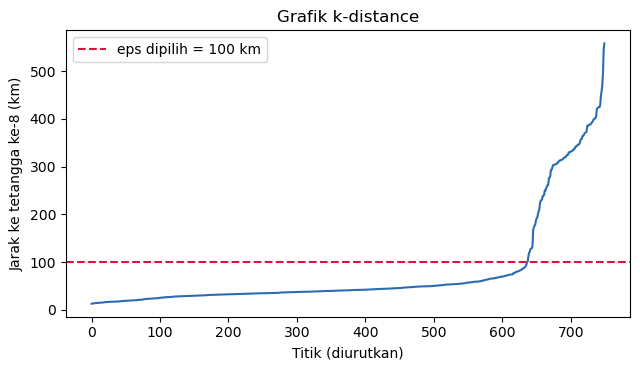

In [5]:
X = np.radians(data[["lat", "lon"]].values)    # PENTING: urutan (lat, lon) dalam radian

nn = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric="haversine").fit(X)
jarak, _ = nn.kneighbors(X)
kdist_km = np.sort(jarak[:, -1]) * R_BUMI

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(kdist_km, color="#2b6cb0")
ax.axhline(EPS_KM, color="crimson", ls="--", label=f"eps dipilih = {EPS_KM} km")
ax.set_xlabel("Titik (diurutkan)")
ax.set_ylabel(f"Jarak ke tetangga ke-{MIN_SAMPLES} (km)")
ax.set_title("Grafik k-distance")
ax.legend()
plt.tight_layout()
plt.show()

### 4.5 Menjalankan DBSCAN dan membuat tabel ringkasan
Perhatikan `eps` harus dibagi `R_BUMI`: haversine di scikit-learn bekerja dalam **radian**, bukan km.

In [6]:
db = DBSCAN(eps=EPS_KM / R_BUMI, min_samples=MIN_SAMPLES, metric="haversine").fit(X)
hasil = data.copy()
hasil["klaster"] = db.labels_                  # -1 berarti noise

n_klaster = int(hasil.klaster.max() + 1)
n_noise = int((hasil.klaster == -1).sum())
print(f"Klaster ditemukan: {n_klaster}")
print(f"Titik noise      : {n_noise} dari {len(hasil)} ({n_noise / len(hasil):.1%})")

ringkas = (hasil[hasil.klaster >= 0].groupby("klaster").agg(
    jumlah_gempa=("mag", "size"),
    mag_rata2=("mag", "mean"),
    mag_maks=("mag", "max"),
    kedalaman_rata2_km=("kedalaman_km", "mean"),
    lon_pusat_deg=("lon", "mean"),
    lat_pusat_deg=("lat", "mean"),
).round(2))
ringkas.to_csv(os.path.join(OUTPUT_DIR, "ringkasan_klaster.csv"))
ringkas

Klaster ditemukan: 4
Titik noise      : 106 dari 750 (14.1%)


,jumlah_gempa,mag_rata2,mag_maks,kedalaman_rata2_km,lon_pusat_deg,lat_pusat_deg
klaster,,,,,,
0,81,4.41,5.84,11.58,119.86,-1.47
1,186,4.44,6.02,52.99,110.11,-8.30
2,222,4.44,7.24,54.14,98.71,-0.45
3,155,4.40,8.00,49.60,125.75,-6.71


### 4.6 Peta klaster
Ukuran titik mengikuti magnitudo. Titik abu-abu bersilang adalah noise.

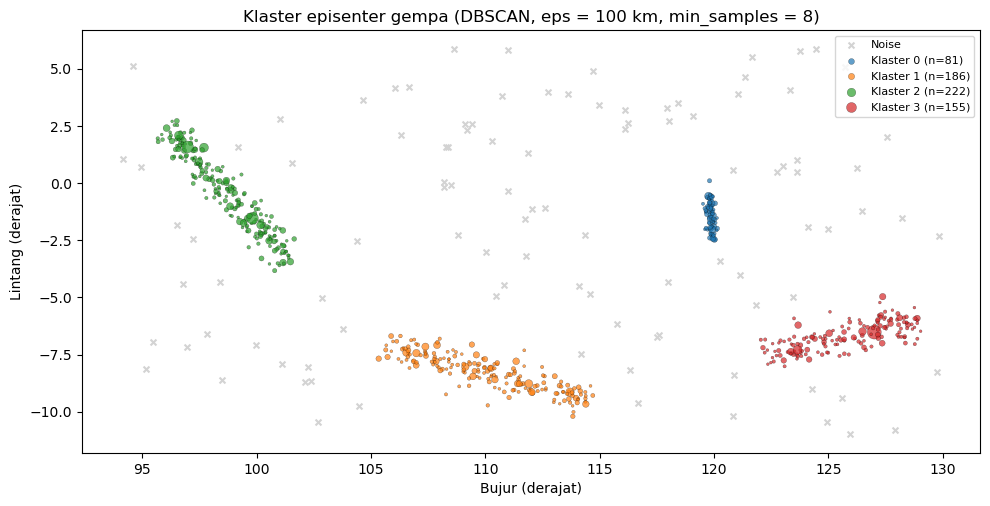

In [7]:
warna = plt.cm.tab10(np.arange(10))
fig, ax = plt.subplots(figsize=(10, 5))
noise = hasil[hasil.klaster == -1]
ax.scatter(noise.lon, noise.lat, c="lightgray", marker="x", s=18, label="Noise")
for k in range(n_klaster):
    d = hasil[hasil.klaster == k]
    ax.scatter(d.lon, d.lat, s=(d.mag - 3) ** 2 * 4, color=warna[k % 10], alpha=0.7,
               edgecolor="k", linewidth=0.2, label=f"Klaster {k} (n={len(d)})")
ax.set_xlabel("Bujur (derajat)")
ax.set_ylabel("Lintang (derajat)")
ax.set_title("Klaster episenter gempa (DBSCAN, eps = %d km, min_samples = %d)" % (EPS_KM, MIN_SAMPLES))
ax.set_aspect("equal")
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "peta_klaster.png"), dpi=150)
plt.show()

---
## 5. Result

Bagian ini sengaja memisahkan **observasi** (angka yang dihitung langsung), **inferensi** (tafsiran), dan **keterbatasan**, seperti anjuran Bab 2.1.

In [8]:
print("OBSERVASI (dihitung dari data):")
print(f"- DBSCAN menemukan {n_klaster} klaster dan {n_noise} titik noise dari {n_input} gempa.")
for k, baris in ringkas.iterrows():
    print(f"- Klaster {k}: {int(baris.jumlah_gempa)} gempa, pusat sekitar "
          f"(lon {baris.lon_pusat_deg:.1f}, lat {baris.lat_pusat_deg:.1f} derajat), "
          f"magnitudo maks {baris.mag_maks:.1f}, kedalaman rata-rata {baris.kedalaman_rata2_km:.0f} km.")
print()
print("INFERENSI (tafsiran, perlu data pendukung untuk data nyata):")
print("- Klaster yang memanjang mengikuti garis menyerupai pola busur subduksi atau sesar;")
print("  klaster kecil dan sempit dengan kedalaman dangkal menyerupai sesar aktif.")
print()
print("KETERBATASAN:")
print("- Data ini sintetis, jadi hasilnya tidak boleh dibaca sebagai fakta tentang wilayah nyata.")
print("- Hasil bergantung pada eps dan min_samples (lihat Check 4).")
print("- Hanya lokasi episenter yang dipakai; waktu dan kedalaman tidak ikut dikelompokkan.")

OBSERVASI (dihitung dari data):
- DBSCAN menemukan 4 klaster dan 106 titik noise dari 750 gempa.
- Klaster 0: 81 gempa, pusat sekitar (lon 119.9, lat -1.5 derajat), magnitudo maks 5.8, kedalaman rata-rata 12 km.
- Klaster 1: 186 gempa, pusat sekitar (lon 110.1, lat -8.3 derajat), magnitudo maks 6.0, kedalaman rata-rata 53 km.
- Klaster 2: 222 gempa, pusat sekitar (lon 98.7, lat -0.5 derajat), magnitudo maks 7.2, kedalaman rata-rata 54 km.
- Klaster 3: 155 gempa, pusat sekitar (lon 125.8, lat -6.7 derajat), magnitudo maks 8.0, kedalaman rata-rata 50 km.

INFERENSI (tafsiran, perlu data pendukung untuk data nyata):
- Klaster yang memanjang mengikuti garis menyerupai pola busur subduksi atau sesar;
  klaster kecil dan sempit dengan kedalaman dangkal menyerupai sesar aktif.

KETERBATASAN:
- Data ini sintetis, jadi hasilnya tidak boleh dibaca sebagai fakta tentang wilayah nyata.
- Hasil bergantung pada eps dan min_samples (lihat Check 4).
- Hanya lokasi episenter yang dipakai; waktu dan ked

---
## 6. Optional Check

Kata "optional" di buku tidak berarti boleh dilewati untuk klaim penting. Yang berubah hanya *seberapa banyak* pengecekan, sesuai risikonya. Di sini ada 4 check ringan.

In [9]:
checks = {}

# Check 1: jumlah baris tidak berubah (prinsip: data tidak boleh hilang)
checks["jumlah_baris_sama"] = (len(hasil) == n_input)

# Check 2: tiap klaster berisi minimal MIN_SAMPLES titik
checks["tiap_klaster_min_samples"] = bool((ringkas.jumlah_gempa >= MIN_SAMPLES).all())

# Check 3: hitung manual satu jarak haversine, bandingkan dengan scikit-learn
a = np.radians([data.lat.iloc[0], data.lon.iloc[0]])
b = np.radians([data.lat.iloc[1], data.lon.iloc[1]])
dphi, dlam = b[0] - a[0], b[1] - a[1]
h = np.sin(dphi / 2) ** 2 + np.cos(a[0]) * np.cos(b[0]) * np.sin(dlam / 2) ** 2
d_manual = 2 * R_BUMI * np.arcsin(np.sqrt(h))
d_sklearn = haversine_distances([a], [b])[0, 0] * R_BUMI
checks["haversine_manual_sama_sklearn"] = bool(abs(d_manual - d_sklearn) < 1e-6)
print(f"Check 3: jarak manual = {d_manual:.3f} km, scikit-learn = {d_sklearn:.3f} km")

# Check 4: seberapa sensitif hasil terhadap eps? (ARI hanya bisa karena data sintetis)
ada_zona_asli = "zona_asli" in hasil.columns      # False kalau memakai data nyata
if ada_zona_asli:
    zona_kode = hasil["zona_asli"].astype("category").cat.codes
baris = []
for eps_km in [EPS_KM * 0.5, EPS_KM, EPS_KM * 1.5]:
    lab = DBSCAN(eps=eps_km / R_BUMI, min_samples=MIN_SAMPLES, metric="haversine").fit_predict(X)
    baris.append({"eps_km": eps_km, "jumlah_klaster": int(lab.max() + 1),
                  "persen_noise": round(float((lab == -1).mean() * 100), 1),
                  "ARI_vs_zona_asli": round(float(adjusted_rand_score(zona_kode, lab)), 3) if ada_zona_asli else None})
sens = pd.DataFrame(baris)
if ada_zona_asli:
    checks["klaster_sesuai_zona_asli(ARI>0.8)"] = bool(sens.loc[sens.eps_km == EPS_KM, "ARI_vs_zona_asli"].iloc[0] > 0.8)

print()
for nama, lolos in checks.items():
    print(("LOLOS  " if lolos else "GAGAL  ") + nama)
print("\nSensitivitas terhadap eps (ARI: 1 = persis zona asli, 0 = acak):")
sens

Check 3: jarak manual = 1773.331 km, scikit-learn = 1773.331 km

LOLOS  jumlah_baris_sama
LOLOS  tiap_klaster_min_samples
LOLOS  haversine_manual_sama_sklearn
LOLOS  klaster_sesuai_zona_asli(ARI>0.8)

Sensitivitas terhadap eps (ARI: 1 = persis zona asli, 0 = acak):


,eps_km,jumlah_klaster,persen_noise,ARI_vs_zona_asli
0,50.0,7,20.7,0.708
1,100.0,4,14.1,0.960
2,150.0,4,13.2,0.942


**Cara membaca Check 4:** kalau `eps` dikecilkan, satu zona pecah menjadi beberapa klaster kecil dan noise bertambah. Kalau dibesarkan, zona yang berbeda bisa menyatu. Jadi jangan pernah melaporkan satu hasil DBSCAN tanpa menyebut `eps` dan `min_samples`-nya.

---
## 7. Run record

Run record mencatat bukti eksekusi: apa yang dijalankan, pada input apa, dengan versi apa, dan check mana yang lolos. Inilah yang membedakan recipe dari sekadar jawaban chat. Sel di bawah membuat file `run_record.json`. **Setiap kali kamu menjalankannya di komputermu, rekamannya ikut diperbarui dengan data lingkunganmu.**

In [10]:
with open(CSV_PATH, "rb") as f:
    sha_input = hashlib.sha256(f.read()).hexdigest()

semua_lolos = all(checks.values())
run_record = {
    "recipe_id": "R-SES-001",
    "prompt_id": "P-SES-001",
    "status": "Executed" if semua_lolos else "Partial",
    "catatan_status": "Dijalankan penuh pada data SINTETIS. Belum diuji pada katalog gempa nyata.",
    "waktu_eksekusi": pd.Timestamp.now().isoformat(timespec="seconds"),
    "lingkungan": {"python": platform.python_version(), "numpy": np.__version__,
                   "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
                   "os": platform.system()},
    "input": {"file": CSV_PATH, "sha256": sha_input, "baris": n_input},
    "parameter": {"eps_km": EPS_KM, "min_samples": MIN_SAMPLES, "seed": 42},
    "output": {"jumlah_klaster": n_klaster, "titik_noise": n_noise,
               "file": ["ringkasan_klaster.csv", "peta_klaster.png", "run_record.json"]},
    "checks": checks,
}
with open(os.path.join(OUTPUT_DIR, "run_record.json"), "w", encoding="utf-8") as f:
    json.dump(run_record, f, indent=2, ensure_ascii=False)

print(json.dumps(run_record, indent=2, ensure_ascii=False))
print("\nFile di", OUTPUT_DIR + ":", sorted(os.listdir(OUTPUT_DIR)))

{
  "recipe_id": "R-SES-001",
  "prompt_id": "P-SES-001",
  "status": "Executed",
  "catatan_status": "Dijalankan penuh pada data SINTETIS. Belum diuji pada katalog gempa nyata.",
  "waktu_eksekusi": "2026-10-20T14:08:15",
  "lingkungan": {
    "python": "3.12.12",
    "numpy": "2.4.2",
    "pandas": "3.0.0",
    "scikit-learn": "1.7.1",
    "os": "Windows"
  },
  "input": {
    "file": "results/r-ses-001\\katalog_sintetis.csv",
    "sha256": "f004329a0156aee94e8298539a65cf6e5482a6e8fb82c028708c6d246bac5912",
    "baris": 750
  },
  "parameter": {
    "eps_km": 100,
    "min_samples": 8,
    "seed": 42
  },
  "output": {
    "jumlah_klaster": 4,
    "titik_noise": 106,
    "file": [
      "ringkasan_klaster.csv",
      "peta_klaster.png",
      "run_record.json"
    ]
  },
  "checks": {
    "jumlah_baris_sama": true,
    "tiap_klaster_min_samples": true,
    "haversine_manual_sama_sklearn": true,
    "klaster_sesuai_zona_asli(ARI>0.8)": true
  }
}

File di results/r-ses-001: ['katalog_